In [1]:
from google.colab import drive
drive.mount("/content/drive")

import sys

sys.path.insert(
    0, "/content/drive/MyDrive/ArteryAI/src"
)

from config import *

print("Project connected:", ROOT)

Mounted at /content/drive
Project connected: /content/drive/MyDrive/ArteryAI


###Import Libraries

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
import json
import time

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from preprocessing import augment_pair

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

MODEL_DIR.mkdir(parents=True, exist_ok=True)

OUT = M2 / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

for folder in ["masks", "overlays", "boundaries",
               "attention_maps", "training"]:
    (OUT / folder).mkdir(
        parents=True, exist_ok=True
    )

Device: cuda
GPU: Tesla T4


###Dataset Loading & Data Augmentation

In [3]:
class ArteryDataset(Dataset):

    def __init__(self, split, multiclass=False):

        path = PROCESSED_DIR / "syntax" / split

        self.images = np.load(
            path / "images.npy"
        )

        mask_file = (
            "multiclass_masks.npy"
            if multiclass
            else "binary_masks.npy"
        )

        self.masks = np.load(path / mask_file)

        self.ids = np.load(
            path / "image_ids.npy"
        )

        self.training = split == "train"
        self.multiclass = multiclass

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image = self.images[index].copy()
        mask = self.masks[index].copy()

        if self.training:

            if self.multiclass:
                # Preserve anatomical class orientation.
                if np.random.rand() < 0.5:
                    image = np.clip(
                        image * np.random.uniform(0.9, 1.1),
                        0, 1
                    )
            else:
                image, mask = augment_pair(image, mask)

        image = torch.from_numpy(
            np.ascontiguousarray(image)
        ).float().unsqueeze(0)

        mask = torch.from_numpy(
            np.ascontiguousarray(mask)
        )

        if self.multiclass:
            mask = mask.long()
        else:
            mask = mask.float().unsqueeze(0)

        return image, mask


def create_loaders(multiclass=False):

    return {
        split: DataLoader(
            ArteryDataset(split, multiclass),
            batch_size=BATCH_SIZE,
            shuffle=(split == "train"),
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )
        for split in ["train", "val", "test"]
    }


loaders = create_loaders()

images, masks = next(iter(loaders["train"]))

print("Image batch:", images.shape)
print("Mask batch:", masks.shape)

for split, loader in loaders.items():
    print(split, len(loader.dataset))

Image batch: torch.Size([8, 1, 256, 256])
Mask batch: torch.Size([8, 1, 256, 256])
train 1000
val 200
test 300


###Save reusable model architectures

In [4]:
%%writefile /content/drive/MyDrive/ArteryAI/src/segmentation.py

import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):

    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class AttentionGate(nn.Module):

    def __init__(self, channels):
        super().__init__()

        hidden = max(channels // 2, 1)

        self.Wx = nn.Conv2d(channels, hidden, 1)
        self.Wg = nn.Conv2d(channels, hidden, 1)

        self.psi = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(hidden, 1, 1),
            nn.Sigmoid()
        )

        self.attention_map = None

    def forward(self, x, g):

        alpha = self.psi(
            self.Wx(x) + self.Wg(g)
        )

        self.attention_map = alpha.detach()

        return x * alpha


class UNet(nn.Module):

    def __init__(self, out_channels=1,
                 attention=False, base=16):

        super().__init__()

        self.attention = attention

        self.enc1 = DoubleConv(1, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(
            base * 4, base * 8
        )

        self.up3 = nn.ConvTranspose2d(
            base * 8, base * 4, 2, stride=2
        )

        self.up2 = nn.ConvTranspose2d(
            base * 4, base * 2, 2, stride=2
        )

        self.up1 = nn.ConvTranspose2d(
            base * 2, base, 2, stride=2
        )

        self.dec3 = DoubleConv(base * 8, base * 4)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.dec1 = DoubleConv(base * 2, base)

        if attention:
            self.att3 = AttentionGate(base * 4)
            self.att2 = AttentionGate(base * 2)
            self.att1 = AttentionGate(base)

        self.output = nn.Conv2d(
            base, out_channels, 1
        )

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.up3(b)
        s3 = self.att3(e3, d3) if self.attention else e3
        d3 = self.dec3(torch.cat([d3, s3], dim=1))

        d2 = self.up2(d3)
        s2 = self.att2(e2, d2) if self.attention else e2
        d2 = self.dec2(torch.cat([d2, s2], dim=1))

        d1 = self.up1(d2)
        s1 = self.att1(e1, d1) if self.attention else e1
        d1 = self.dec1(torch.cat([d1, s1], dim=1))

        return self.output(d1)


class AttentionUNet(UNet):

    def __init__(self, out_channels=1, base=16):

        super().__init__(
            out_channels=out_channels,
            attention=True,
            base=base
        )

Overwriting /content/drive/MyDrive/ArteryAI/src/segmentation.py


###Verify Model Architectures

In [5]:
from segmentation import UNet, AttentionUNet

for name, model in [
    ("U-Net", UNet()),
    ("Attention U-Net", AttentionUNet())
]:

    model = model.to(device)
    model.eval()

    with torch.no_grad():

        dummy = torch.randn(
            1, 1, 256, 256
        ).to(device)

        output = model(dummy)

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    print(name)
    print("Parameters:", parameters)
    print("Output shape:", output.shape)
    print("-" * 40)

    del model

U-Net
Parameters: 483153
Output shape: torch.Size([1, 1, 256, 256])
----------------------------------------
Attention U-Net
Parameters: 488700
Output shape: torch.Size([1, 1, 256, 256])
----------------------------------------


###Loss Function & Class Imbalance Handling

In [6]:
train_masks = loaders["train"].dataset.masks

positive = np.count_nonzero(train_masks)
negative = train_masks.size - positive

assert positive > 0, "No foreground in training masks"

pos_weight = min(
    negative / positive,
    20.0
)

print("Foreground pixels:", positive)
print("Background pixels:", negative)
print("Positive class weight:", pos_weight)


class BCEDiceLoss(nn.Module):

    def __init__(self):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                [pos_weight]
            ).to(device)
        )

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)

        intersection = (
            probs * targets
        ).sum(dim=(1, 2, 3))

        dice = (
            2 * intersection + 1e-6
        ) / (
            probs.sum(dim=(1, 2, 3))
            + targets.sum(dim=(1, 2, 3))
            + 1e-6
        )

        dice_loss = 1 - dice.mean()

        return 0.5 * bce_loss + 0.5 * dice_loss


criterion = BCEDiceLoss()

Foreground pixels: 2142058
Background pixels: 63393942
Positive class weight: 20.0


###Complete Model Training Engine

In [7]:
def dice_score(logits, targets):

    preds = (
        torch.sigmoid(logits) >= 0.5
    ).float()

    intersection = (
        preds * targets
    ).sum(dim=(1, 2, 3))

    denominator = (
        preds.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
    )

    dice = (
        2 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    return dice.mean().item()


def train_model(model, name,
                epochs=EPOCHS,
                lr=LEARNING_RATE,
                patience=5):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    use_amp = device.type == "cuda"

    scaler = torch.amp.GradScaler(
        "cuda", enabled=use_amp
    )

    best_dice = -1.0
    wait = 0
    history = []

    start_time = time.time()

    checkpoint = MODEL_DIR / f"{name}.pth"

    for epoch in range(epochs):

        model.train()

        train_loss = 0.0
        train_dice = 0.0
        train_count = 0

        progress = tqdm(
            loaders["train"],
            desc=f"{name} Epoch {epoch+1}/{epochs}"
        )

        for images, masks in progress:

            images = images.to(device)
            masks = masks.to(device)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):

                logits = model(images)
                loss = criterion(logits, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            n = images.size(0)

            train_loss += loss.item() * n

            train_dice += dice_score(
                logits.detach().float(), masks
            ) * n

            train_count += n

            progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        model.eval()

        val_loss = 0.0
        val_dice = 0.0
        val_count = 0

        with torch.no_grad():

            for images, masks in loaders["val"]:

                images = images.to(device)
                masks = masks.to(device)

                logits = model(images)

                loss = criterion(logits, masks)

                n = images.size(0)

                val_loss += loss.item() * n

                val_dice += dice_score(
                    logits, masks
                ) * n

                val_count += n

        train_loss /= train_count
        train_dice /= train_count

        val_loss /= val_count
        val_dice /= val_count

        scheduler.step(val_loss)

        record = {
            "model": name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_dice": train_dice,
            "val_dice": val_dice,
            "learning_rate":
                optimizer.param_groups[0]["lr"],
            "elapsed_seconds":
                time.time() - start_time
        }

        history.append(record)

        print(
            f"Epoch {epoch+1}: "
            f"Train Loss={train_loss:.4f}, "
            f"Val Loss={val_loss:.4f}, "
            f"Val Dice={val_dice:.4f}"
        )

        if val_dice > best_dice:

            best_dice = val_dice
            wait = 0

            torch.save(
                model.state_dict(),
                checkpoint
            )

            print("Best checkpoint saved!")

        else:

            wait += 1

            if wait >= patience:
                print("Early stopping triggered")
                break

        pd.DataFrame(history).to_csv(
            OUT / "training" / f"{name}_history.csv",
            index=False
        )

    pd.DataFrame(history).to_csv(
        OUT / "training" / f"{name}_history.csv",
        index=False
    )

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location=device,
            weights_only=True
        )
    )

    print("Best validation Dice:", best_dice)
    print("Training time:", time.time() - start_time)
    print("Checkpoint:", checkpoint)

    return model, pd.DataFrame(history)

###Train Baseline U-Net

In [8]:
unet, unet_history = train_model(
    UNet(),
    name="unet",
    epochs=EPOCHS,
    lr=0.001
)

unet Epoch 1/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1: Train Loss=0.6840, Val Loss=0.5826, Val Dice=0.5972
Best checkpoint saved!


unet Epoch 2/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2: Train Loss=0.5069, Val Loss=0.4805, Val Dice=0.5917


unet Epoch 3/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 3: Train Loss=0.4019, Val Loss=0.3879, Val Dice=0.6583
Best checkpoint saved!


... (20 outputs left out)

unet Epoch 14/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 14: Train Loss=0.2539, Val Loss=0.3158, Val Dice=0.7339


unet Epoch 15/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 15: Train Loss=0.2488, Val Loss=0.2992, Val Dice=0.7317
Early stopping triggered
Best validation Dice: 0.735623435974121
Training time: 100.09338569641113
Checkpoint: /content/drive/MyDrive/ArteryAI/models/checkpoints/unet.pth


###Validation Threshold Optimization

In [9]:
unet.eval()

val_probs = []
val_targets = []

with torch.no_grad():

    for images, masks in tqdm(
        loaders["val"],
        desc="Validation inference"
    ):

        images = images.to(device)

        probs = torch.sigmoid(unet(images))

        val_probs.append(
            probs.cpu().numpy()
        )

        val_targets.append(
            masks.numpy()
        )

val_probs = np.concatenate(val_probs)
val_targets = np.concatenate(val_targets)

threshold_results = []

for threshold in np.arange(0.1, 0.91, 0.05):

    preds = (
        val_probs >= threshold
    ).astype(np.float32)

    intersection = (
        preds * val_targets
    ).sum(axis=(1, 2, 3))

    denominator = (
        preds.sum(axis=(1, 2, 3))
        + val_targets.sum(axis=(1, 2, 3))
    )

    dice = (
        (2 * intersection + 1e-6)
        / (denominator + 1e-6)
    ).mean()

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "dice": float(dice)
    })

threshold_df = pd.DataFrame(
    threshold_results
)

best_row = threshold_df.loc[
    threshold_df["dice"].idxmax()
]

BEST_UNET_THRESHOLD = float(
    best_row["threshold"]
)

print("Best threshold:", BEST_UNET_THRESHOLD)

print(
    "Optimized validation Dice:",
    round(best_row["dice"] * 100, 2),
    "%"
)

display(threshold_df)

threshold_df.to_csv(
    OUT / "training/unet_threshold_tuning.csv",
    index=False
)

Validation inference:   0%|          | 0/25 [00:00<?, ?it/s]

Best threshold: 0.85
Optimized validation Dice: 76.34 %


,threshold,dice
0,0.10,0.656794
1,0.15,0.678162
2,0.20,0.692197
3,0.25,0.702794
4,0.30,0.711385
5,0.35,0.718726
6,0.40,0.724907
7,0.45,0.730524
8,0.50,0.735623
9,0.55,0.740554


###Threshold Optimization Graph

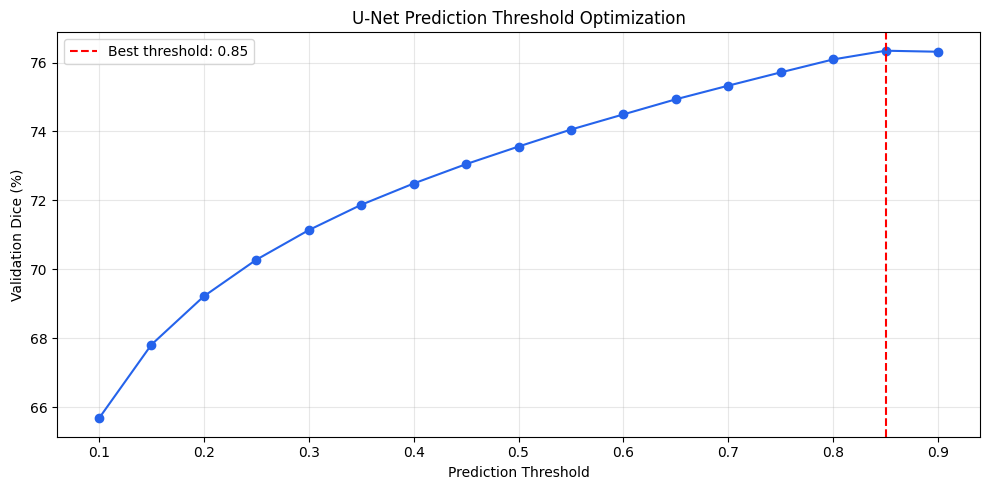

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["dice"] * 100,
    marker="o",
    color="#2563EB"
)

plt.axvline(
    BEST_UNET_THRESHOLD,
    color="red",
    linestyle="--",
    label=f"Best threshold: {BEST_UNET_THRESHOLD}"
)

plt.title("U-Net Prediction Threshold Optimization")
plt.xlabel("Prediction Threshold")
plt.ylabel("Validation Dice (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "training/unet_threshold_optimization.png",
    dpi=200
)

plt.show()

###Save Optimized Model Configuration

In [11]:
unet_config = {
    "model_name": "U-Net",
    "version": "1.0",
    "dataset": "ARCADE",
    "input_size": [256, 256],
    "training_samples": 1000,
    "validation_samples": 200,
    "best_epoch": int(
        unet_history.loc[
            unet_history["val_dice"].idxmax(),
            "epoch"
        ]
    ),
    "completed_epochs": len(unet_history),
    "best_validation_dice": float(
        unet_history["val_dice"].max()
    ),
    "optimized_threshold": BEST_UNET_THRESHOLD,
    "optimized_validation_dice": float(
        best_row["dice"]
    ),
    "checkpoint": "unet.pth"
}

with open(
    MODEL_DIR / "unet_config.json", "w"
) as f:

    json.dump(unet_config, f, indent=4)

print("Model configuration saved!")

Model configuration saved!


###Train Attention U-Net

In [12]:
attention_unet, attention_history = train_model(
    AttentionUNet(),
    name="attention_unet",
    epochs=50,
    lr=0.001,
    patience=10
)

attention_unet Epoch 1/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1: Train Loss=0.6788, Val Loss=0.5904, Val Dice=0.4753
Best checkpoint saved!


attention_unet Epoch 2/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2: Train Loss=0.4856, Val Loss=0.4457, Val Dice=0.6093
Best checkpoint saved!


attention_unet Epoch 3/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 3: Train Loss=0.3805, Val Loss=0.3732, Val Dice=0.6823
Best checkpoint saved!


... (58 outputs left out)

attention_unet Epoch 33/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 33: Train Loss=0.1933, Val Loss=0.3075, Val Dice=0.7588


attention_unet Epoch 34/50:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 34: Train Loss=0.1931, Val Loss=0.3052, Val Dice=0.7586
Early stopping triggered
Best validation Dice: 0.7632850790023804
Training time: 258.7384626865387
Checkpoint: /content/drive/MyDrive/ArteryAI/models/checkpoints/attention_unet.pth


###Collect Validation Predictions

In [13]:
import numpy as np
import pandas as pd
import torch
import json

from tqdm.auto import tqdm

unet.eval()
attention_unet.eval()

unet_probs = []
attention_probs = []
val_targets = []

with torch.inference_mode():

    for images, masks in tqdm(
        loaders["val"],
        desc="Collecting validation predictions"
    ):

        images = images.to(device)

        p1 = torch.sigmoid(unet(images))
        p2 = torch.sigmoid(attention_unet(images))

        unet_probs.append(p1.cpu().numpy())
        attention_probs.append(p2.cpu().numpy())
        val_targets.append(masks.numpy())

unet_probs = np.concatenate(unet_probs)
attention_probs = np.concatenate(attention_probs)

val_targets = np.concatenate(
    val_targets
).astype(bool)

print("U-Net:", unet_probs.shape)
print("Attention U-Net:", attention_probs.shape)
print("Ground truth:", val_targets.shape)

U-Net: (200, 1, 256, 256)
Attention U-Net: (200, 1, 256, 256)
Ground truth: (200, 1, 256, 256)


###Optimize Ensemble Weights and Threshold

In [14]:
def calculate_dice(probs, targets, threshold):

    preds = probs >= threshold

    axes = (1, 2, 3)

    intersection = np.logical_and(
        preds, targets
    ).sum(axis=axes)

    denominator = (
        preds.sum(axis=axes)
        + targets.sum(axis=axes)
    )

    dice = (
        2 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    return float(dice.mean())


results = []

for weight in tqdm(
    np.linspace(0, 1, 11),
    desc="Optimizing ensemble"
):

    combined = (
        weight * unet_probs
        + (1 - weight) * attention_probs
    )

    for threshold in np.linspace(0.1, 0.9, 17):

        dice = calculate_dice(
            combined,
            val_targets,
            threshold
        )

        results.append({
            "unet_weight": round(float(weight), 2),
            "attention_weight": round(
                float(1 - weight), 2
            ),
            "threshold": round(float(threshold), 2),
            "validation_dice": dice
        })

ensemble_df = pd.DataFrame(results)

ensemble_df = ensemble_df.sort_values(
    "validation_dice",
    ascending=False
).reset_index(drop=True)

best = ensemble_df.iloc[0]

BEST_WEIGHT = float(best["unet_weight"])
BEST_THRESHOLD = float(best["threshold"])

print("Best U-Net weight:", BEST_WEIGHT)

print(
    "Best Attention U-Net weight:",
    1 - BEST_WEIGHT
)

print("Best threshold:", BEST_THRESHOLD)

print(
    "Optimized validation Dice:",
    round(best["validation_dice"] * 100, 2),
    "%"
)

display(ensemble_df.head(10))

ensemble_df.to_csv(
    OUT / "training/ensemble_optimization.csv",
    index=False
)

Optimizing ensemble:   0%|          | 0/11 [00:00<?, ?it/s]

Best U-Net weight: 0.1
Best Attention U-Net weight: 0.9
Best threshold: 0.85
Optimized validation Dice: 78.33 %


,unet_weight,attention_weight,threshold,validation_dice
0,0.1,0.9,0.85,0.783279
1,0.2,0.8,0.85,0.783242
2,0.3,0.7,0.85,0.782897
3,0.1,0.9,0.90,0.782728
4,0.3,0.7,0.80,0.782483
5,0.2,0.8,0.80,0.782467
6,0.4,0.6,0.85,0.782390
7,0.4,0.6,0.80,0.782198
8,0.0,1.0,0.90,0.782177
9,0.5,0.5,0.85,0.781992


###Compare All Optimized Models

In [15]:
comparison = []

for name, weight in [
    ("U-Net", 1.0),
    ("Attention U-Net", 0.0)
]:

    rows = ensemble_df[
        ensemble_df["unet_weight"] == weight
    ]

    row = rows.iloc[0]

    comparison.append({
        "Model": name,
        "Threshold": float(row["threshold"]),
        "U-Net Weight": weight,
        "Attention Weight": 1 - weight,
        "Validation Dice": float(
            row["validation_dice"]
        )
    })

# Best genuine ensemble
mixed = ensemble_df[
    ensemble_df["unet_weight"].between(0.1, 0.9)
].iloc[0]

comparison.append({
    "Model": "Weighted Ensemble",
    "Threshold": float(mixed["threshold"]),
    "U-Net Weight": float(mixed["unet_weight"]),
    "Attention Weight": float(
        mixed["attention_weight"]
    ),
    "Validation Dice": float(
        mixed["validation_dice"]
    )
})

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

comparison_df.to_csv(
    OUT / "training/optimized_model_comparison.csv",
    index=False
)

selected = comparison_df.loc[
    comparison_df["Validation Dice"].idxmax()
]

print("Selected model:", selected["Model"])

print(
    "Best validation Dice:",
    selected["Validation Dice"]
)

,Model,Threshold,U-Net Weight,Attention Weight,Validation Dice
0,U-Net,0.85,1.0,0.0,0.763421
1,Attention U-Net,0.90,0.0,1.0,0.782177
2,Weighted Ensemble,0.85,0.1,0.9,0.783279


Selected model: Weighted Ensemble
Best validation Dice: 0.7832789315830445


###Save Best Model Configuration

In [16]:
best_config = {
    "selected_model": str(selected["Model"]),
    "version": "1.0",
    "dataset": "ARCADE",
    "input_size": [256, 256],
    "unet_weight": float(selected["U-Net Weight"]),
    "attention_weight": float(
        selected["Attention Weight"]
    ),
    "threshold": float(selected["Threshold"]),
    "validation_dice": float(
        selected["Validation Dice"]
    ),
    "training_samples": 1000,
    "validation_samples": 200,
    "test_samples": 300,
    "unet_checkpoint": "unet.pth",
    "attention_checkpoint": "attention_unet.pth",
    "selection_metric": "Validation Dice",
    "clinical_validation": False
}

with open(
    MODEL_DIR / "best_segmentation_config.json",
    "w"
) as f:

    json.dump(best_config, f, indent=4)

print(json.dumps(best_config, indent=4))
print("Best model configuration saved!")

{
    "selected_model": "Weighted Ensemble",
    "version": "1.0",
    "dataset": "ARCADE",
    "input_size": [
        256,
        256
    ],
    "unet_weight": 0.1,
    "attention_weight": 0.9,
    "threshold": 0.85,
    "validation_dice": 0.7832789315830445,
    "training_samples": 1000,
    "validation_samples": 200,
    "test_samples": 300,
    "unet_checkpoint": "unet.pth",
    "attention_checkpoint": "attention_unet.pth",
    "selection_metric": "Validation Dice",
    "clinical_validation": false
}
Best model configuration saved!


###Model Comparison Graph

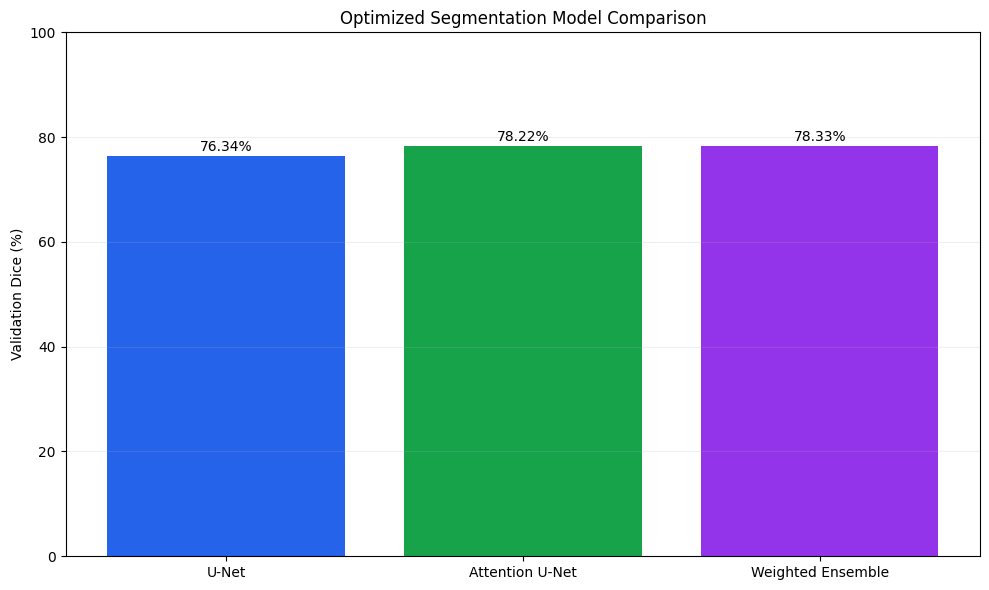

In [17]:
plt.figure(figsize=(10, 6))

scores = comparison_df["Validation Dice"] * 100

bars = plt.bar(
    comparison_df["Model"],
    scores,
    color=["#2563EB", "#16A34A", "#9333EA"]
)

for bar, score in zip(bars, scores):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.title("Optimized Segmentation Model Comparison")
plt.ylabel("Validation Dice (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUT / "training/optimized_model_comparison.png",
    dpi=200
)

plt.show()

###Multi-class Dataset & Model Initialization

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
import time

from tqdm.auto import tqdm
from segmentation import UNet

# Training configuration
MULTICLASS_EPOCHS = 25
MULTICLASS_LR = 0.001
MULTICLASS_PATIENCE = 7

# Load class mapping
with open(DATA_DIR / "class_mapping.json") as f:
    mapping = json.load(f)["syntax"]

NUM_CLASSES = len(mapping)

# Reverse mapping
reverse_mapping = {
    int(index): int(label)
    for label, index in mapping.items()
}

# Create multi-class data loaders
multi_loaders = create_loaders(
    multiclass=True
)

print("Total mapped classes:", NUM_CLASSES)

print("\nClass mapping:")
print(mapping)

print("\nDataset distribution:")

for split, loader in multi_loaders.items():
    print(split, len(loader.dataset))

# Calculate class distribution
multi_masks = multi_loaders["train"].dataset.masks

assert multi_masks.min() >= 0
assert multi_masks.max() < NUM_CLASSES

counts = np.bincount(
    multi_masks.flatten(),
    minlength=NUM_CLASSES
)

# Handle class imbalance
weights = np.zeros(
    NUM_CLASSES,
    dtype=np.float32
)

present = counts > 0

weights[present] = (
    1.0 / np.sqrt(counts[present])
)

weights[present] /= weights[present].mean()

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("\nTraining class pixel counts:")
print(counts)

print("\nClass weights:")
print(class_weights)

print("\nClasses absent from training:")
print(np.where(~present)[0])

# Initialize multi-class U-Net
multi_model = UNet(
    out_channels=NUM_CLASSES
).to(device)

# Weighted Cross Entropy Loss
multi_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Optimizer
multi_optimizer = torch.optim.AdamW(
    multi_model.parameters(),
    lr=MULTICLASS_LR,
    weight_decay=1e-4
)

# Learning rate scheduler
multi_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        multi_optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )
)

# Mixed precision training
use_amp = device.type == "cuda"

multi_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("\nMulti-class model initialized!")

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in multi_model.parameters()
    )
)

Total mapped classes: 26

Class mapping:
{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, '10': 10, '11': 11, '12': 12, '13': 13, '14': 14, '15': 15, '16': 16, '17': 17, '18': 18, '19': 19, '20': 20, '21': 21, '22': 22, '23': 23, '24': 24, '25': 25}

Dataset distribution:
train 1000
val 200
test 300

Training class pixel counts:
[63393942   166227   171711   165480   120186   147969   204260   171379
   142611   117624    30985     5973      273   126936    37787    84277
   149399    60301    24494    16653    80551    12384    15892     9095
    41142    38469]

Class weights:
tensor([0.0186, 0.3635, 0.3577, 0.3644, 0.4275, 0.3853, 0.3279, 0.3580, 0.3925,
        0.4322, 0.8420, 1.9178, 8.9705, 0.4160, 0.7625, 0.5106, 0.3835, 0.6036,
        0.9470, 1.1486, 0.5222, 1.3319, 1.1757, 1.5542, 0.7307, 0.7557],
       device='cuda:0')

Classes absent from training:
[]

Multi-class model initialized!
Total parameters: 483578


###Multi-class Loss & Dice Function

In [19]:
def multiclass_dice_loss(logits, targets):

    probs = torch.softmax(
        logits.float(),
        dim=1
    )

    one_hot = F.one_hot(
        targets,
        num_classes=NUM_CLASSES
    )

    one_hot = one_hot.permute(
        0, 3, 1, 2
    ).float()

    dims = (0, 2, 3)

    intersection = (
        probs * one_hot
    ).sum(dim=dims)

    denominator = (
        probs.sum(dim=dims)
        + one_hot.sum(dim=dims)
    )

    dice = (
        2 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    # Exclude background and absent target classes
    valid = one_hot.sum(dim=dims) > 0
    valid[0] = False

    if not valid.any():
        return logits.sum() * 0

    return 1 - dice[valid].mean()


def combined_multiclass_loss(logits, targets):

    ce = multi_criterion(
        logits,
        targets
    )

    dice = multiclass_dice_loss(
        logits,
        targets
    )

    return 0.5 * ce + 0.5 * dice


def update_confusion_matrix(
    confusion,
    logits,
    targets
):

    predictions = logits.argmax(dim=1)

    indices = (
        targets.flatten() * NUM_CLASSES
        + predictions.flatten()
    )

    matrix = torch.bincount(
        indices,
        minlength=NUM_CLASSES ** 2
    ).reshape(
        NUM_CLASSES,
        NUM_CLASSES
    )

    confusion += matrix

    return confusion


def macro_dice_from_confusion(confusion):

    confusion = confusion.float()

    tp = confusion.diag()

    actual = confusion.sum(dim=1)
    predicted = confusion.sum(dim=0)

    dice = (
        2 * tp
    ) / (
        actual + predicted + 1e-8
    )

    valid = actual > 0

    # Exclude background
    valid[0] = False

    if not valid.any():
        return 0.0

    return dice[valid].mean().item()


print("Multi-class loss and metrics ready!")

Multi-class loss and metrics ready!


###Complete Multi-class Model Training

In [20]:
multi_history = []

best_multi_dice = -1.0

wait = 0

start_time = time.time()

multi_checkpoint = (
    MODEL_DIR / "multiclass_unet.pth"
)

for epoch in range(MULTICLASS_EPOCHS):

    # =========================
    # TRAINING
    # =========================

    multi_model.train()

    train_loss = 0.0
    train_count = 0

    train_confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long,
        device=device
    )

    progress = tqdm(
        multi_loaders["train"],
        desc=(
            f"Multi-class Epoch "
            f"{epoch+1}/{MULTICLASS_EPOCHS}"
        )
    )

    for images, masks in progress:

        images = images.to(device)
        masks = masks.to(device)

        multi_optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):

            logits = multi_model(images)

            loss = combined_multiclass_loss(
                logits,
                masks
            )

        multi_scaler.scale(loss).backward()

        multi_scaler.step(
            multi_optimizer
        )

        multi_scaler.update()

        n = images.size(0)

        train_loss += loss.item() * n
        train_count += n

        with torch.no_grad():

            train_confusion = (
                update_confusion_matrix(
                    train_confusion,
                    logits.detach(),
                    masks
                )
            )

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_count

    train_dice = macro_dice_from_confusion(
        train_confusion
    )

    # =========================
    # VALIDATION
    # =========================

    multi_model.eval()

    val_loss = 0.0
    val_count = 0

    val_confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():

        for images, masks in multi_loaders["val"]:

            images = images.to(device)
            masks = masks.to(device)

            logits = multi_model(images)

            # Unweighted validation CE
            # includes all mapped classes
            ce = F.cross_entropy(
                logits,
                masks
            )

            dice_loss = multiclass_dice_loss(
                logits,
                masks
            )

            loss = (
                0.5 * ce
                + 0.5 * dice_loss
            )

            n = images.size(0)

            val_loss += loss.item() * n
            val_count += n

            val_confusion = (
                update_confusion_matrix(
                    val_confusion,
                    logits,
                    masks
                )
            )

    val_loss /= val_count

    val_dice = macro_dice_from_confusion(
        val_confusion
    )

    # Learning rate scheduling
    multi_scheduler.step(val_dice)

    current_lr = (
        multi_optimizer.param_groups[0]["lr"]
    )

    # Save training history
    multi_history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "val_loss": val_loss,

        "train_macro_dice": train_dice,

        "val_macro_dice": val_dice,

        "learning_rate": current_lr,

        "elapsed_seconds":
            time.time() - start_time
    })

    print(
        f"\nEpoch {epoch+1}: "
        f"Train Loss={train_loss:.4f}, "
        f"Val Loss={val_loss:.4f}, "
        f"Train Dice={train_dice:.4f}, "
        f"Val Dice={val_dice:.4f}"
    )

    # Best checkpoint selection
    if val_dice > best_multi_dice:

        best_multi_dice = val_dice

        wait = 0

        torch.save(
            multi_model.state_dict(),
            multi_checkpoint
        )

        print("Best multi-class checkpoint saved!")

    else:

        wait += 1

    # Save CSV after every epoch
    pd.DataFrame(multi_history).to_csv(
        OUT / "training/multiclass_history.csv",
        index=False
    )

    # Early stopping
    if wait >= MULTICLASS_PATIENCE:

        print("Early stopping triggered!")

        break


# Load best model
multi_model.load_state_dict(

    torch.load(
        multi_checkpoint,
        map_location=device,
        weights_only=True
    )
)

multi_model.eval()

multi_history_df = pd.DataFrame(
    multi_history
)

print("\n" + "=" * 60)

print("Multi-class training completed!")

print(
    "Best Validation Macro Dice:",
    round(best_multi_dice * 100, 2),
    "%"
)

print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("Checkpoint:", multi_checkpoint)

print("=" * 60)

Multi-class Epoch 1/25:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 1: Train Loss=1.8241, Val Loss=1.2804, Train Dice=0.0097, Val Dice=0.0151
Best multi-class checkpoint saved!


Multi-class Epoch 2/25:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 2: Train Loss=1.3311, Val Loss=0.7631, Train Dice=0.0625, Val Dice=0.0581
Best multi-class checkpoint saved!


Multi-class Epoch 3/25:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 3: Train Loss=1.1337, Val Loss=0.6332, Train Dice=0.0988, Val Dice=0.1033
Best multi-class checkpoint saved!


... (40 outputs left out)

Multi-class Epoch 24/25:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 24: Train Loss=0.4316, Val Loss=0.3996, Train Dice=0.4678, Val Dice=0.2954


Multi-class Epoch 25/25:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 25: Train Loss=0.3717, Val Loss=0.3792, Train Dice=0.5156, Val Dice=0.3396
Best multi-class checkpoint saved!

Multi-class training completed!
Best Validation Macro Dice: 33.96 %
Training time: 232.79 seconds
Checkpoint: /content/drive/MyDrive/ArteryAI/models/checkpoints/multiclass_unet.pth


###Multi-class Training Graphs

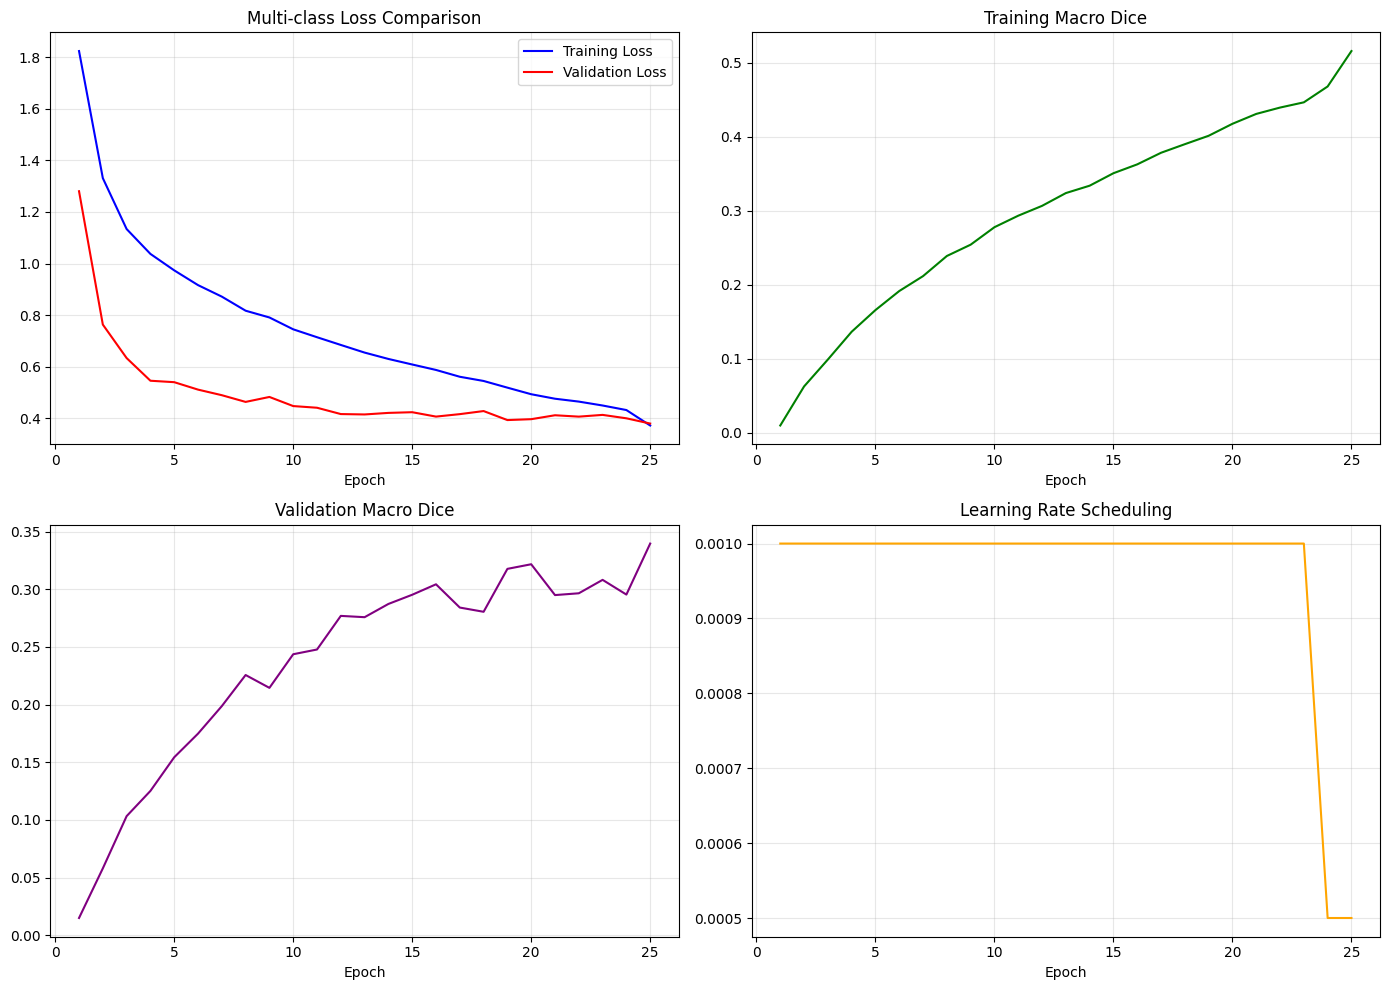

In [21]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

epochs = multi_history_df["epoch"]

# Loss comparison
axes[0, 0].plot(
    epochs,
    multi_history_df["train_loss"],
    label="Training Loss",
    color="blue"
)

axes[0, 0].plot(
    epochs,
    multi_history_df["val_loss"],
    label="Validation Loss",
    color="red"
)

axes[0, 0].set_title(
    "Multi-class Loss Comparison"
)

axes[0, 0].legend()

# Training Dice
axes[0, 1].plot(
    epochs,
    multi_history_df["train_macro_dice"],
    color="green"
)

axes[0, 1].set_title(
    "Training Macro Dice"
)

# Validation Dice
axes[1, 0].plot(
    epochs,
    multi_history_df["val_macro_dice"],
    color="purple"
)

axes[1, 0].set_title(
    "Validation Macro Dice"
)

# Learning rate
axes[1, 1].plot(
    epochs,
    multi_history_df["learning_rate"],
    color="orange"
)

axes[1, 1].set_title(
    "Learning Rate Scheduling"
)

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUT / "training/multiclass_training_graphs.png",
    dpi=200
)

plt.show()

###Multi-class Validation & Per-class Evaluation

In [22]:
multi_model.eval()

confusion = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.long,
    device=device
)

with torch.inference_mode():

    for images, masks in tqdm(
        multi_loaders["val"],
        desc="Multi-class validation"
    ):

        images = images.to(device)
        masks = masks.to(device)

        logits = multi_model(images)

        confusion = update_confusion_matrix(
            confusion,
            logits,
            masks
        )

cm = confusion.cpu().numpy()

records = []

for c in range(NUM_CLASSES):

    tp = int(cm[c, c])

    fp = int(cm[:, c].sum() - tp)

    fn = int(cm[c, :].sum() - tp)

    tn = int(cm.sum() - tp - fp - fn)

    dice = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn > 0
        else np.nan
    )

    iou = (
        tp / (tp + fp + fn)
        if tp + fp + fn > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if tn + fp > 0
        else np.nan
    )

    records.append({

        "Class_Index": c,

        "Original_Label":
            reverse_mapping[c],

        "Dice": dice,

        "IoU": iou,

        "Precision": precision,

        "Recall": recall,

        "Specificity": specificity,

        "Ground_Truth_Pixels": tp + fn,

        "Predicted_Pixels": tp + fp
    })

class_metrics_df = pd.DataFrame(records)

display(class_metrics_df)

# Exclude background and classes
# without validation ground truth
foreground_metrics = class_metrics_df[
    (class_metrics_df["Class_Index"] != 0)
    & (class_metrics_df["Ground_Truth_Pixels"] > 0)
]

print(
    "Foreground Macro Dice:",
    foreground_metrics["Dice"].mean()
)

print(
    "Foreground Macro IoU:",
    foreground_metrics["IoU"].mean()
)

print(
    "Pixel Accuracy:",
    np.trace(cm) / cm.sum()
)

class_metrics_df.to_csv(
    OUT / "multiclass_validation_metrics.csv",
    index=False
)

np.save(
    OUT / "multiclass_validation_confusion.npy",
    cm
)

print("Per-class evaluation saved!")

Multi-class validation:   0%|          | 0/25 [00:00<?, ?it/s]

,Class_Index,Original_Label,Dice,IoU,Precision,Recall,Specificity,Ground_Truth_Pixels,Predicted_Pixels
0,0,0,0.988178,0.976632,0.994851,0.981594,0.863334,12637405,12469007
1,1,1,0.666667,0.500000,0.678658,0.655092,0.999237,32168,31051
2,2,2,0.632536,0.462561,0.638376,0.626802,0.999035,35520,34876
3,3,3,0.643258,0.474120,0.617547,0.671204,0.999024,30706,33374
4,4,4,0.544952,0.374525,0.500496,0.598075,0.999000,21917,26190
5,5,5,0.718768,0.560998,0.730035,0.707844,0.999185,40694,39457
6,6,6,0.577141,0.405621,0.484376,0.713854,0.997422,44320,65317
7,7,7,0.574489,0.403006,0.526390,0.632263,0.998389,37021,44467
8,8,8,0.592019,0.420473,0.508894,0.707601,0.998359,31416,43683
9,9,9,0.219139,0.123052,0.136071,0.562590,0.993588,23486,97104


Foreground Macro Dice: 0.3395867183533514
Foreground Macro IoU: 0.23229222019605822
Pixel Accuracy: 0.9662075042724609
Per-class evaluation saved!


###Multi-class Performance Graph

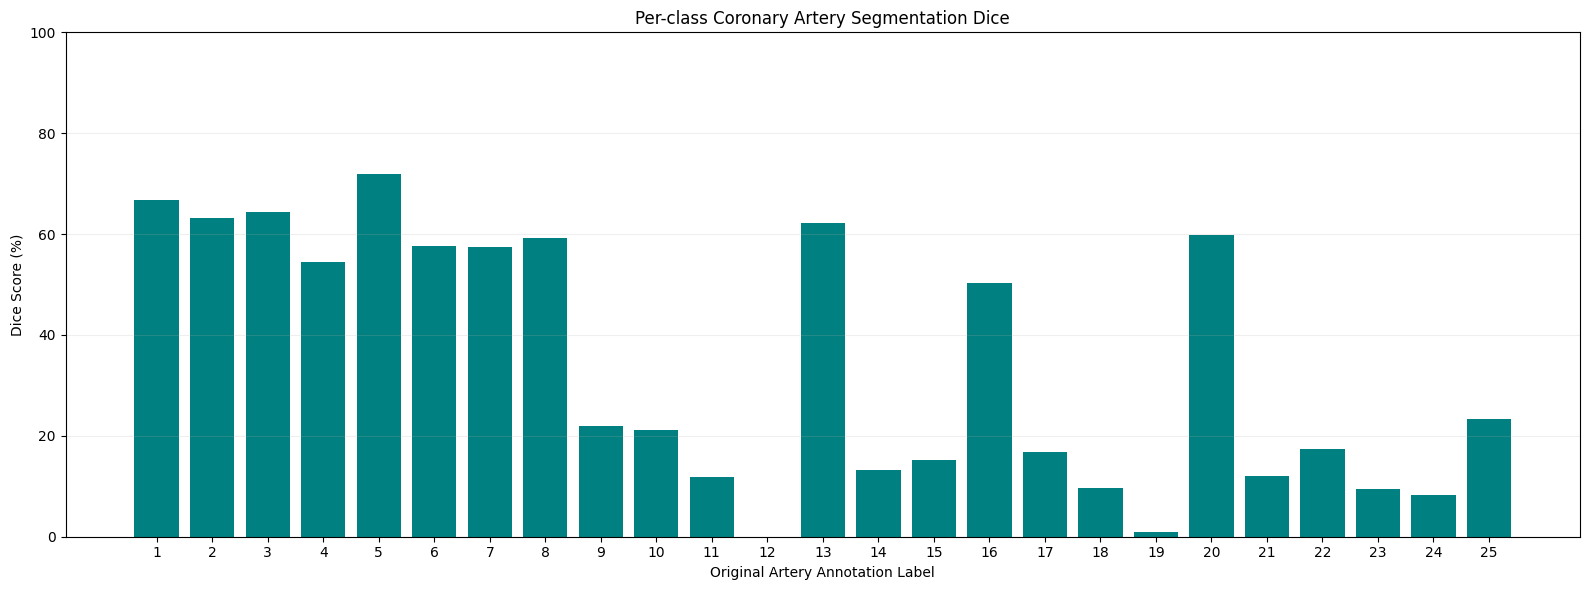

In [23]:
plot_df = foreground_metrics.copy()

plt.figure(figsize=(16, 6))

plt.bar(
    plot_df["Original_Label"].astype(str),
    plot_df["Dice"] * 100,
    color="teal"
)

plt.title(
    "Per-class Coronary Artery Segmentation Dice"
)

plt.xlabel("Original Artery Annotation Label")

plt.ylabel("Dice Score (%)")

plt.ylim(0, 100)

plt.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    OUT / "multiclass_per_class_dice.png",
    dpi=200
)

plt.show()

###Multi-class Segmentation Visualization

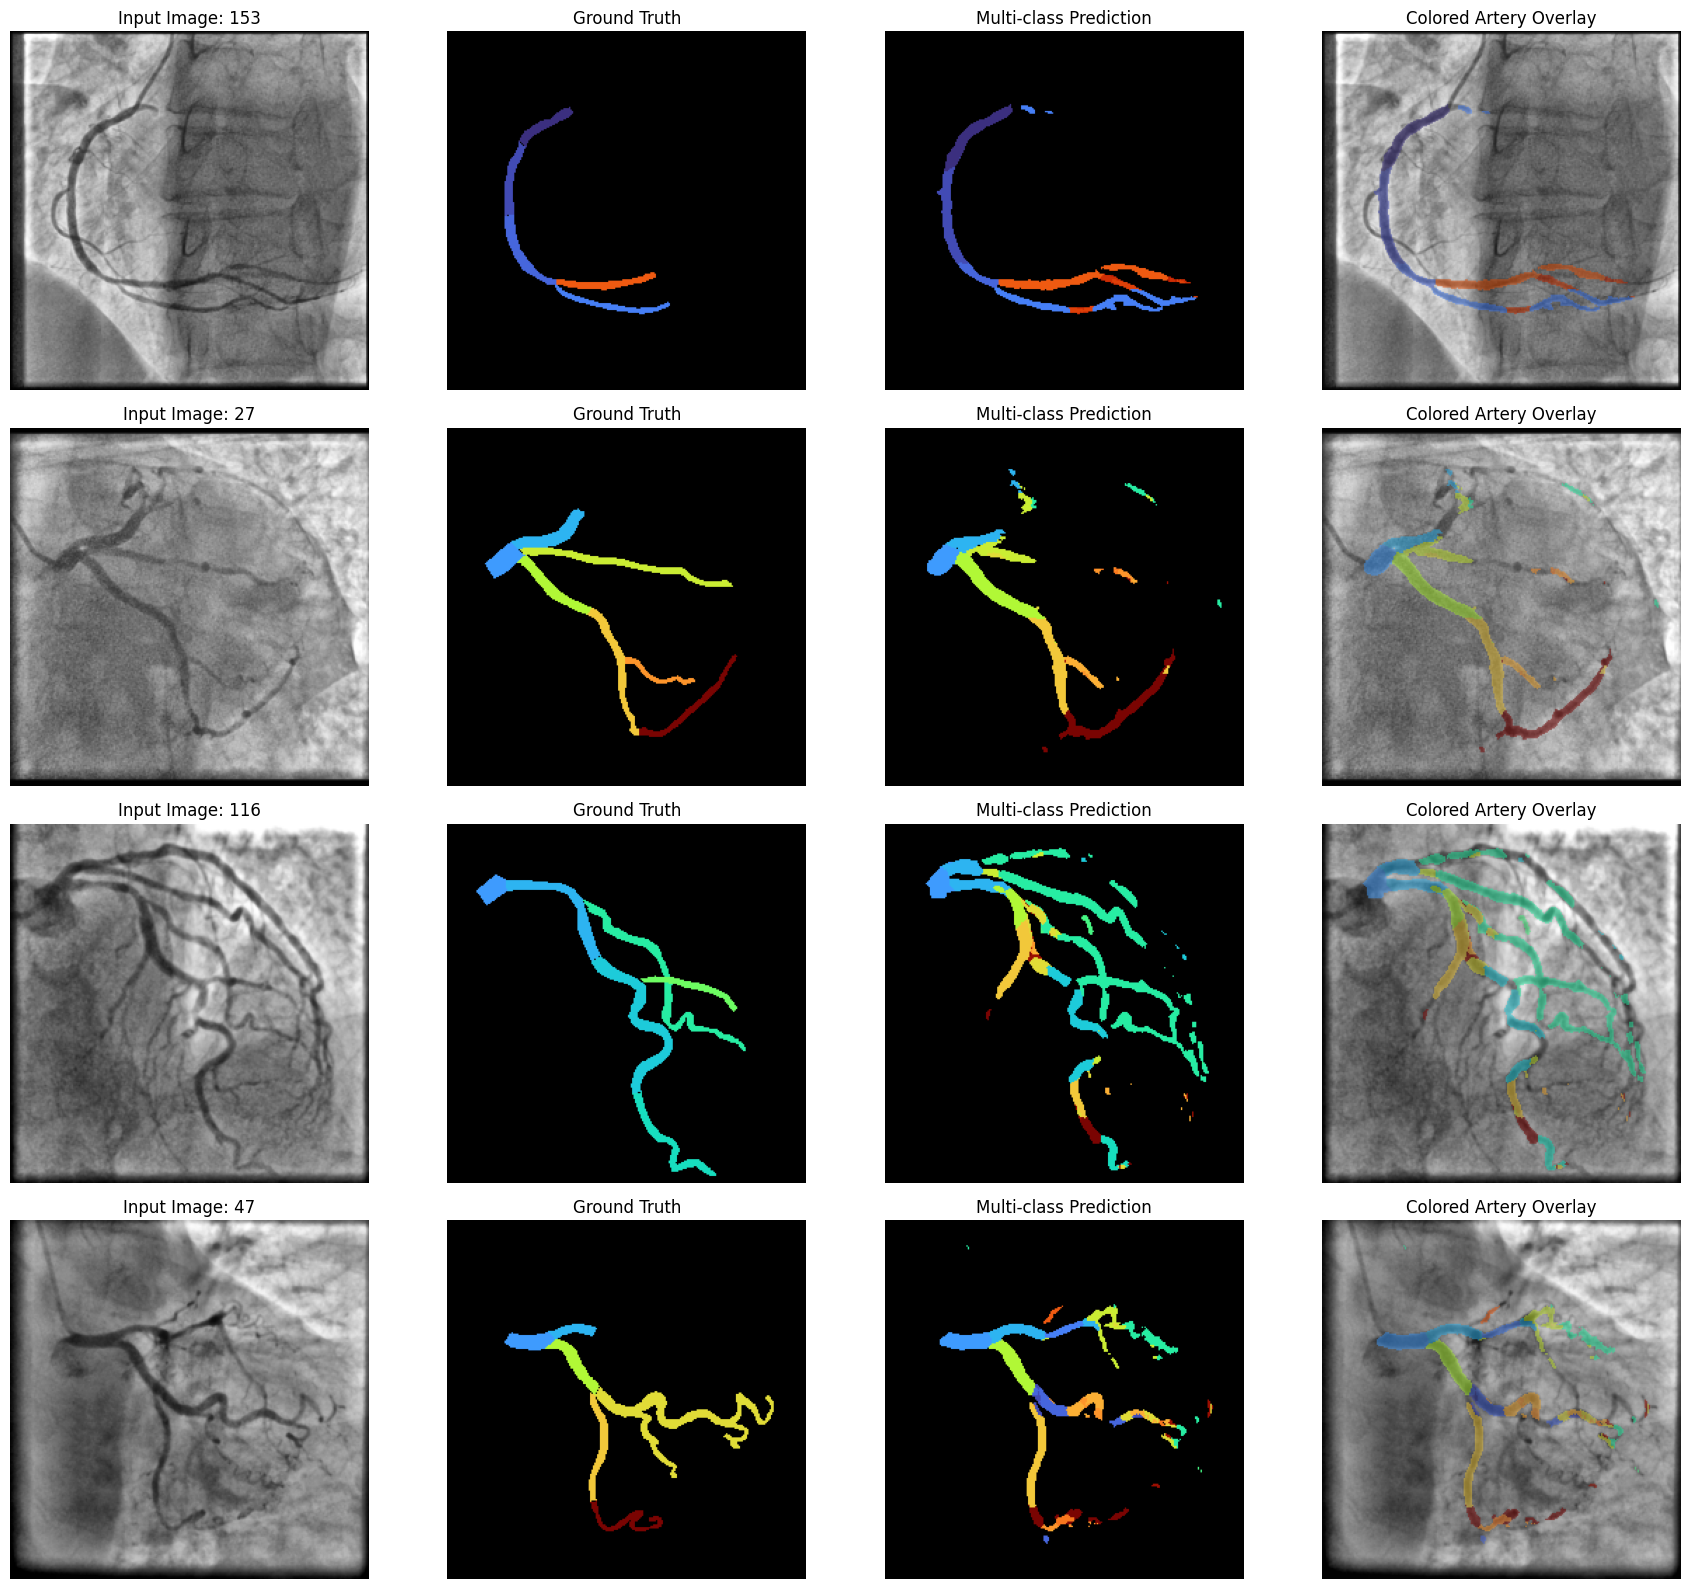

In [24]:
from matplotlib.colors import ListedColormap

multi_model.eval()

multi_val_data = ArteryDataset(
    "val",
    multiclass=True
)

# Fixed colors for consistent class visualization
colors = plt.cm.turbo(
    np.linspace(0, 1, NUM_CLASSES)
)

# Background is black
colors[0] = [0, 0, 0, 1]

class_cmap = ListedColormap(colors)

fig, axes = plt.subplots(
    4, 4,
    figsize=(18, 16)
)

for i in range(4):

    image, target = multi_val_data[i]

    image_id = multi_val_data.ids[i]

    x = image.unsqueeze(0).to(device)

    with torch.inference_mode():

        logits = multi_model(x)

        pred = logits.argmax(
            dim=1
        )[0].cpu().numpy()

    original = image[0].numpy()

    target = target.numpy()

    rgb = np.stack(
        [original] * 3,
        axis=-1
    )

    colored_mask = colors[pred][..., :3]

    overlay = rgb.copy()

    region = pred > 0

    overlay[region] = (
        0.5 * rgb[region]
        + 0.5 * colored_mask[region]
    )

    axes[i, 0].imshow(
        original,
        cmap="gray"
    )

    axes[i, 0].set_title(
        f"Input Image: {image_id}"
    )

    axes[i, 1].imshow(
        target,
        cmap=class_cmap,
        vmin=0,
        vmax=NUM_CLASSES - 1
    )

    axes[i, 1].set_title(
        "Ground Truth"
    )

    axes[i, 2].imshow(
        pred,
        cmap=class_cmap,
        vmin=0,
        vmax=NUM_CLASSES - 1
    )

    axes[i, 2].set_title(
        "Multi-class Prediction"
    )

    axes[i, 3].imshow(overlay)

    axes[i, 3].set_title(
        "Colored Artery Overlay"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    OUT / "multiclass_segmentation_visualization.png",
    dpi=200
)

plt.show()

###Save Model Configuration

In [25]:
best_epoch_row = multi_history_df.loc[
    multi_history_df["val_macro_dice"].idxmax()
]

multi_config = {

    "model_name": "Multi-class U-Net",

    "version": "1.0",

    "dataset": "ARCADE Syntax",

    "input_size": [256, 256],

    "num_classes": NUM_CLASSES,

    "class_mapping": mapping,

    "training_samples":
        len(multi_loaders["train"].dataset),

    "validation_samples":
        len(multi_loaders["val"].dataset),

    "test_samples":
        len(multi_loaders["test"].dataset),

    "completed_epochs":
        len(multi_history_df),

    "best_epoch":
        int(best_epoch_row["epoch"]),

    "best_validation_macro_dice":
        float(best_multi_dice),

    "validation_macro_iou":
        float(foreground_metrics["IoU"].mean()),

    "loss_function":
        "Weighted Cross Entropy + Dice Loss",

    "optimizer": "AdamW",

    "checkpoint": "multiclass_unet.pth",

    "clinical_validation": False
}

with open(
    MODEL_DIR / "multiclass_config.json",
    "w"
) as f:

    json.dump(
        multi_config,
        f,
        indent=4
    )

print(json.dumps(
    multi_config,
    indent=4
))

print("\nMulti-class segmentation completed!")

{
    "model_name": "Multi-class U-Net",
    "version": "1.0",
    "dataset": "ARCADE Syntax",
    "input_size": [
        256,
        256
    ],
    "num_classes": 26,
    "class_mapping": {
        "0": 0,
        "1": 1,
        "2": 2,
        "3": 3,
        "4": 4,
        "5": 5,
        "6": 6,
        "7": 7,
        "8": 8,
        "9": 9,
        "10": 10,
        "11": 11,
        "12": 12,
        "13": 13,
        "14": 14,
        "15": 15,
        "16": 16,
        "17": 17,
        "18": 18,
        "19": 19,
        "20": 20,
        "21": 21,
        "22": 22,
        "23": 23,
        "24": 24,
        "25": 25
    },
    "training_samples": 1000,
    "validation_samples": 200,
    "test_samples": 300,
    "completed_epochs": 25,
    "best_epoch": 25,
    "best_validation_macro_dice": 0.33958670496940613,
    "validation_macro_iou": 0.23229222019605822,
    "loss_function": "Weighted Cross Entropy + Dice Loss",
    "optimizer": "AdamW",
    "checkpoint": "multiclas

###Backup Existing Model

In [26]:
import shutil

backup_path = (
    MODEL_DIR / "multiclass_unet_v1.pth"
)

if not backup_path.exists():
    shutil.copy2(
        MODEL_DIR / "multiclass_unet.pth",
        backup_path
    )

OLD_MACRO_DICE = float(
    foreground_metrics["Dice"].mean()
)

print("Previous model backed up!")
print("Previous Macro Dice:", OLD_MACRO_DICE)

Previous model backed up!
Previous Macro Dice: 0.3395867183533514


###Improved Loss Function

In [27]:
class FocalDiceLoss(nn.Module):

    def __init__(self, weights, gamma=2.0):

        super().__init__()

        self.register_buffer(
            "weights", weights
        )

        self.gamma = gamma

    def forward(self, logits, targets):

        logits = logits.float()

        ce = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-ce)

        pixel_weights = self.weights[targets]

        focal = (
            pixel_weights
            * (1 - pt) ** self.gamma
            * ce
        )

        focal = (
            focal.sum()
            / pixel_weights.sum().clamp_min(1e-8)
        )

        dice = multiclass_dice_loss(
            logits,
            targets
        )

        return 0.5 * focal + 0.5 * dice


improved_criterion = FocalDiceLoss(
    class_weights,
    gamma=2.0
).to(device)

print("Focal + Dice Loss initialized!")

Focal + Dice Loss initialized!


###Initialize Fine-tuning

In [28]:
multi_model = UNet(
    out_channels=NUM_CLASSES
).to(device)

multi_model.load_state_dict(
    torch.load(
        backup_path,
        map_location=device,
        weights_only=True
    )
)

fine_optimizer = torch.optim.AdamW(
    multi_model.parameters(),
    lr=0.0003,
    weight_decay=1e-4
)

fine_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        fine_optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )
)

fine_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=device.type == "cuda"
)

FINE_EPOCHS = 30
FINE_PATIENCE = 10

print("Fine-tuning initialized!")

Fine-tuning initialized!


###Complete Fine-tuning Engine

In [29]:
fine_history = []

best_fine_dice = OLD_MACRO_DICE

wait = 0

start_time = time.time()

fine_checkpoint = (
    MODEL_DIR / "multiclass_unet_v2.pth"
)

# Preserve the previous model if no improvement occurs
torch.save(
    multi_model.state_dict(),
    fine_checkpoint
)

for epoch in range(FINE_EPOCHS):

    multi_model.train()

    train_loss = 0.0
    train_count = 0

    train_cm = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long,
        device=device
    )

    progress = tqdm(
        multi_loaders["train"],
        desc=f"Fine-tuning {epoch+1}/{FINE_EPOCHS}"
    )

    for images, masks in progress:

        images = images.to(device)
        masks = masks.to(device)

        fine_optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):

            logits = multi_model(images)

            loss = improved_criterion(
                logits,
                masks
            )

        fine_scaler.scale(loss).backward()

        fine_scaler.unscale_(fine_optimizer)

        torch.nn.utils.clip_grad_norm_(
            multi_model.parameters(),
            max_norm=1.0
        )

        fine_scaler.step(fine_optimizer)

        fine_scaler.update()

        n = images.size(0)

        train_loss += loss.item() * n
        train_count += n

        with torch.no_grad():

            train_cm = update_confusion_matrix(
                train_cm,
                logits.detach(),
                masks
            )

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_count

    train_dice = macro_dice_from_confusion(
        train_cm
    )

    # Validation

    multi_model.eval()

    val_loss = 0.0
    val_count = 0

    val_cm = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long,
        device=device
    )

    with torch.inference_mode():

        for images, masks in multi_loaders["val"]:

            images = images.to(device)
            masks = masks.to(device)

            logits = multi_model(images)

            loss = improved_criterion(
                logits,
                masks
            )

            n = images.size(0)

            val_loss += loss.item() * n
            val_count += n

            val_cm = update_confusion_matrix(
                val_cm,
                logits,
                masks
            )

    val_loss /= val_count

    val_dice = macro_dice_from_confusion(
        val_cm
    )

    fine_scheduler.step(val_dice)

    fine_history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "val_loss": val_loss,

        "train_macro_dice": train_dice,

        "val_macro_dice": val_dice,

        "learning_rate":
            fine_optimizer.param_groups[0]["lr"]
    })

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss={train_loss:.4f}, "
        f"Val Loss={val_loss:.4f}, "
        f"Train Dice={train_dice:.4f}, "
        f"Val Dice={val_dice:.4f}"
    )

    if val_dice > best_fine_dice:

        best_fine_dice = val_dice

        wait = 0

        torch.save(
            multi_model.state_dict(),
            fine_checkpoint
        )

        print("Improved checkpoint saved!")

    else:

        wait += 1

    pd.DataFrame(fine_history).to_csv(
        OUT / "training/multiclass_finetuning.csv",
        index=False
    )

    if wait >= FINE_PATIENCE:

        print("Early stopping triggered!")

        break


multi_model.load_state_dict(
    torch.load(
        fine_checkpoint,
        map_location=device,
        weights_only=True
    )
)

multi_model.eval()

fine_history_df = pd.DataFrame(fine_history)

print("\nFine-tuning completed!")

print("Previous Dice:", OLD_MACRO_DICE)

print("Best Dice:", best_fine_dice)

print(
    "Improvement:",
    (best_fine_dice - OLD_MACRO_DICE) * 100,
    "percentage points"
)

print(
    "Training time:",
    time.time() - start_time
)

Fine-tuning 1/30:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1: Train Loss=0.2778, Val Loss=0.9742, Train Dice=0.5687, Val Dice=0.3395


Fine-tuning 2/30:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2: Train Loss=0.2627, Val Loss=0.9807, Train Dice=0.5873, Val Dice=0.3317


Fine-tuning 3/30:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 3: Train Loss=0.2540, Val Loss=1.0063, Train Dice=0.5996, Val Dice=0.3378


... (20 outputs left out)

Fine-tuning 14/30:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 14: Train Loss=0.1715, Val Loss=1.2323, Train Dice=0.7189, Val Dice=0.3338


Fine-tuning 15/30:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 15: Train Loss=0.1680, Val Loss=1.2532, Train Dice=0.7252, Val Dice=0.3322
Early stopping triggered!

Fine-tuning completed!
Previous Dice: 0.3395867183533514
Best Dice: 0.34047651290893555
Improvement: 0.08897945555841336 percentage points
Training time: 141.5073697566986


###Compare Previous and Improved Model

,Model,Validation Macro Dice
0,Multi-class U-Net V1,0.339587
1,Multi-class U-Net V2,0.340477


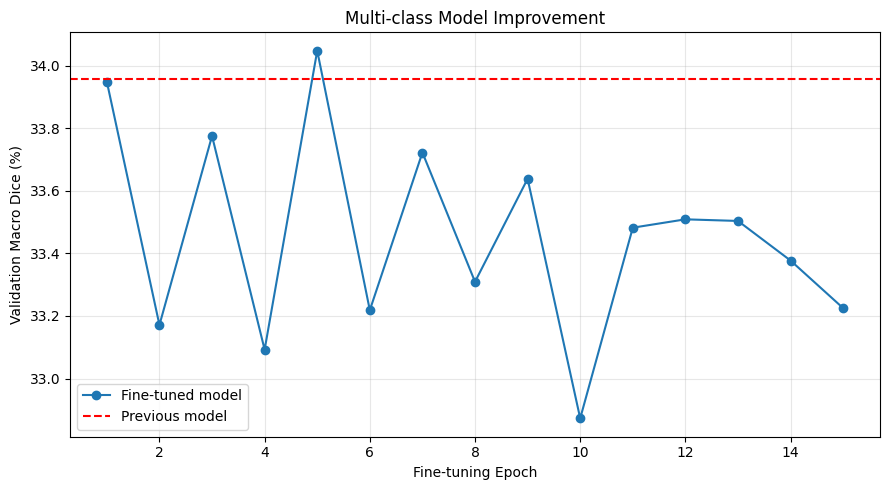

In [30]:
comparison_multi = pd.DataFrame([

    {
        "Model": "Multi-class U-Net V1",
        "Validation Macro Dice": OLD_MACRO_DICE
    },

    {
        "Model": "Multi-class U-Net V2",
        "Validation Macro Dice": best_fine_dice
    }
])

display(comparison_multi)

comparison_multi.to_csv(
    OUT / "training/multiclass_version_comparison.csv",
    index=False
)

plt.figure(figsize=(9, 5))

plt.plot(
    fine_history_df["epoch"],
    fine_history_df["val_macro_dice"] * 100,
    marker="o",
    label="Fine-tuned model"
)

plt.axhline(
    OLD_MACRO_DICE * 100,
    color="red",
    linestyle="--",
    label="Previous model"
)

plt.xlabel("Fine-tuning Epoch")

plt.ylabel("Validation Macro Dice (%)")

plt.title("Multi-class Model Improvement")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUT / "training/multiclass_finetuning.png",
    dpi=200
)

plt.show()

###Automatically Select Best Model

In [31]:
if best_fine_dice > OLD_MACRO_DICE:

    shutil.copy2(
        fine_checkpoint,
        MODEL_DIR / "multiclass_unet.pth"
    )

    selected_multi_version = "2.0"

    print("Improved model selected!")

else:

    selected_multi_version = "1.0"

    print("Previous model retained!")


multi_model.load_state_dict(
    torch.load(
        MODEL_DIR / "multiclass_unet.pth",
        map_location=device,
        weights_only=True
    )
)

multi_model.eval()

print("Selected version:", selected_multi_version)
print("Selected Dice:", best_fine_dice)

Improved model selected!
Selected version: 2.0
Selected Dice: 0.34047651290893555


###Save Updated Model Metadata

In [32]:
with open(
    MODEL_DIR / "multiclass_config.json"
) as f:
    multi_config = json.load(f)

multi_config.update({
    "version": selected_multi_version,
    "validation_macro_dice": float(
        foreground_metrics["Dice"].mean()
    ),
    "validation_macro_iou": float(
        foreground_metrics["IoU"].mean()
    ),
    "validation_pixel_accuracy": float(
        np.trace(cm) / cm.sum()
    ),
    "fine_tuning_loss": "Weighted Focal + Dice",
    "fine_tuning_epochs": len(fine_history_df),
    "checkpoint": "multiclass_unet.pth",
    "clinical_validation": False
})

with open(
    MODEL_DIR / "multiclass_config.json", "w"
) as f:
    json.dump(multi_config, f, indent=4)

print("Updated model configuration saved!")
print(json.dumps(multi_config, indent=4))

Updated model configuration saved!
{
    "model_name": "Multi-class U-Net",
    "version": "2.0",
    "dataset": "ARCADE Syntax",
    "input_size": [
        256,
        256
    ],
    "num_classes": 26,
    "class_mapping": {
        "0": 0,
        "1": 1,
        "2": 2,
        "3": 3,
        "4": 4,
        "5": 5,
        "6": 6,
        "7": 7,
        "8": 8,
        "9": 9,
        "10": 10,
        "11": 11,
        "12": 12,
        "13": 13,
        "14": 14,
        "15": 15,
        "16": 16,
        "17": 17,
        "18": 18,
        "19": 19,
        "20": 20,
        "21": 21,
        "22": 22,
        "23": 23,
        "24": 24,
        "25": 25
    },
    "training_samples": 1000,
    "validation_samples": 200,
    "test_samples": 300,
    "completed_epochs": 25,
    "best_epoch": 25,
    "best_validation_macro_dice": 0.33958670496940613,
    "validation_macro_iou": 0.23229222019605822,
    "loss_function": "Weighted Cross Entropy + Dice Loss",
    "optimizer": "A

###Create postprocessing.py

In [33]:
%%writefile /content/drive/MyDrive/ArteryAI/src/postprocessing.py

import cv2
import numpy as np


# 1. Binary mask post-processing
def postprocess_mask(mask, min_area=8):

    mask = (mask > 0).astype(np.uint8)

    # Morphological closing
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3)
    )

    closed = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Connected component analysis
    count, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            closed,
            connectivity=8
        )
    )

    result = np.zeros_like(mask)

    # Remove small noisy components
    for i in range(1, count):

        area = stats[i, cv2.CC_STAT_AREA]

        if area >= min_area:

            result[labels == i] = 1

    return result


# 2. Vessel boundary extraction
def extract_boundary(mask):

    mask = (mask > 0).astype(np.uint8)

    kernel = np.ones(
        (3, 3),
        dtype=np.uint8
    )

    eroded = cv2.erode(
        mask,
        kernel
    )

    boundary = mask - eroded

    return boundary


# 3. Segmentation overlay generation
def create_overlay(image, mask):

    image = (
        np.clip(image, 0, 1) * 255
    ).astype(np.uint8)

    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_GRAY2RGB
    )

    region = mask > 0

    rgb[region] = (
        rgb[region] * 0.5
        + np.array([0, 255, 0]) * 0.5
    ).astype(np.uint8)

    return rgb

Overwriting /content/drive/MyDrive/ArteryAI/src/postprocessing.py


###Import and Verify Module

In [34]:
import sys
import importlib

from pathlib import Path

SRC_PATH = "/content/drive/MyDrive/ArteryAI/src"

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

importlib.invalidate_caches()

assert Path(
    SRC_PATH,
    "postprocessing.py"
).exists(), "File not found!"

from postprocessing import (
    postprocess_mask,
    extract_boundary,
    create_overlay
)

print("Postprocessing module imported successfully!")

Postprocessing module imported successfully!


###Test All Three Functions

In [35]:
import numpy as np

test_mask = np.zeros(
    (256, 256),
    dtype=np.uint8
)

test_mask[50:150, 100:110] = 1

test_image = np.random.rand(
    256, 256
).astype(np.float32)

cleaned = postprocess_mask(test_mask)

boundary = extract_boundary(cleaned)

overlay = create_overlay(
    test_image,
    cleaned
)

print("Mask shape:", cleaned.shape)
print("Boundary shape:", boundary.shape)
print("Overlay shape:", overlay.shape)

print("All postprocessing functions working!")

Mask shape: (256, 256)
Boundary shape: (256, 256)
Overlay shape: (256, 256, 3)
All postprocessing functions working!


###Generate Final Segmentation Masks

In [36]:
import cv2
import numpy as np
import pandas as pd
import torch
import json

from tqdm.auto import tqdm
from postprocessing import (
    postprocess_mask,
    extract_boundary,
    create_overlay
)

with open(
    MODEL_DIR / "best_segmentation_config.json"
) as f:
    best_config = json.load(f)

for folder in [
    "masks",
    "boundaries",
    "overlays",
    "attention_maps"
]:
    (OUT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

unet.eval()
attention_unet.eval()
multi_model.eval()

test_data = ArteryDataset("test")

records = []

with torch.inference_mode():

    for i in tqdm(
        range(len(test_data)),
        desc="Generating final masks"
    ):

        image, target = test_data[i]

        image_id = test_data.ids[i]

        x = image.unsqueeze(0).to(device)

        original = image[0].numpy()

        # Binary predictions
        p1 = torch.sigmoid(
            unet(x)
        )[0, 0].cpu().numpy()

        p2 = torch.sigmoid(
            attention_unet(x)
        )[0, 0].cpu().numpy()

        # Optimized probability fusion
        probability = (
            best_config["unet_weight"] * p1
            + best_config["attention_weight"] * p2
        )

        raw_mask = (
            probability >= best_config["threshold"]
        ).astype(np.uint8)

        final_mask = postprocess_mask(
            raw_mask
        )

        boundary = extract_boundary(
            final_mask
        )

        overlay = create_overlay(
            original,
            final_mask
        )

        # Multi-class prediction
        multi_pred = multi_model(x).argmax(
            dim=1
        )[0].cpu().numpy()

        # Attention visualization
        attention_map = (
            attention_unet.att1.attention_map
            [0, 0].cpu().numpy()
        )

        # Save binary masks
        cv2.imwrite(
            str(
                OUT / "masks" /
                f"{image_id}_raw.png"
            ),
            raw_mask * 255
        )

        cv2.imwrite(
            str(
                OUT / "masks" /
                f"{image_id}_mask.png"
            ),
            final_mask * 255
        )

        # Save boundary
        cv2.imwrite(
            str(
                OUT / "boundaries" /
                f"{image_id}.png"
            ),
            boundary * 255
        )

        # Save overlay
        cv2.imwrite(
            str(
                OUT / "overlays" /
                f"{image_id}.png"
            ),
            cv2.cvtColor(
                overlay,
                cv2.COLOR_RGB2BGR
            )
        )

        # Save multiclass mask
        np.save(
            OUT / "masks" /
            f"{image_id}_multiclass.npy",
            multi_pred
        )

        # Save probability map
        np.save(
            OUT / "masks" /
            f"{image_id}_probability.npy",
            probability
        )

        plt.imsave(
            OUT / "attention_maps" /
            f"{image_id}.png",
            attention_map,
            cmap="jet"
        )

        records.append({
            "image_id": int(image_id),
            "foreground_pixels": int(
                final_mask.sum()
            ),
            "foreground_percentage": float(
                final_mask.mean() * 100
            ),
            "model": best_config["selected_model"],
            "threshold": best_config["threshold"],
            "status": (
                "processed"
                if final_mask.any()
                else "empty_prediction"
            )
        })

prediction_df = pd.DataFrame(records)

prediction_df.to_csv(
    OUT / "segmentation_predictions.csv",
    index=False
)

display(prediction_df.head())

print("Total processed images:", len(prediction_df))

print("Final mask generation completed!")

Generating final masks:   0%|          | 0/300 [00:00<?, ?it/s]

,image_id,foreground_pixels,foreground_percentage,model,threshold,status
0,262,2698,4.116821,Weighted Ensemble,0.85,processed
1,294,1617,2.467346,Weighted Ensemble,0.85,processed
2,62,2011,3.068542,Weighted Ensemble,0.85,processed
3,254,1576,2.404785,Weighted Ensemble,0.85,processed
4,167,2043,3.117371,Weighted Ensemble,0.85,processed


Total processed images: 300
Final mask generation completed!


###Final Segmentation Visualization

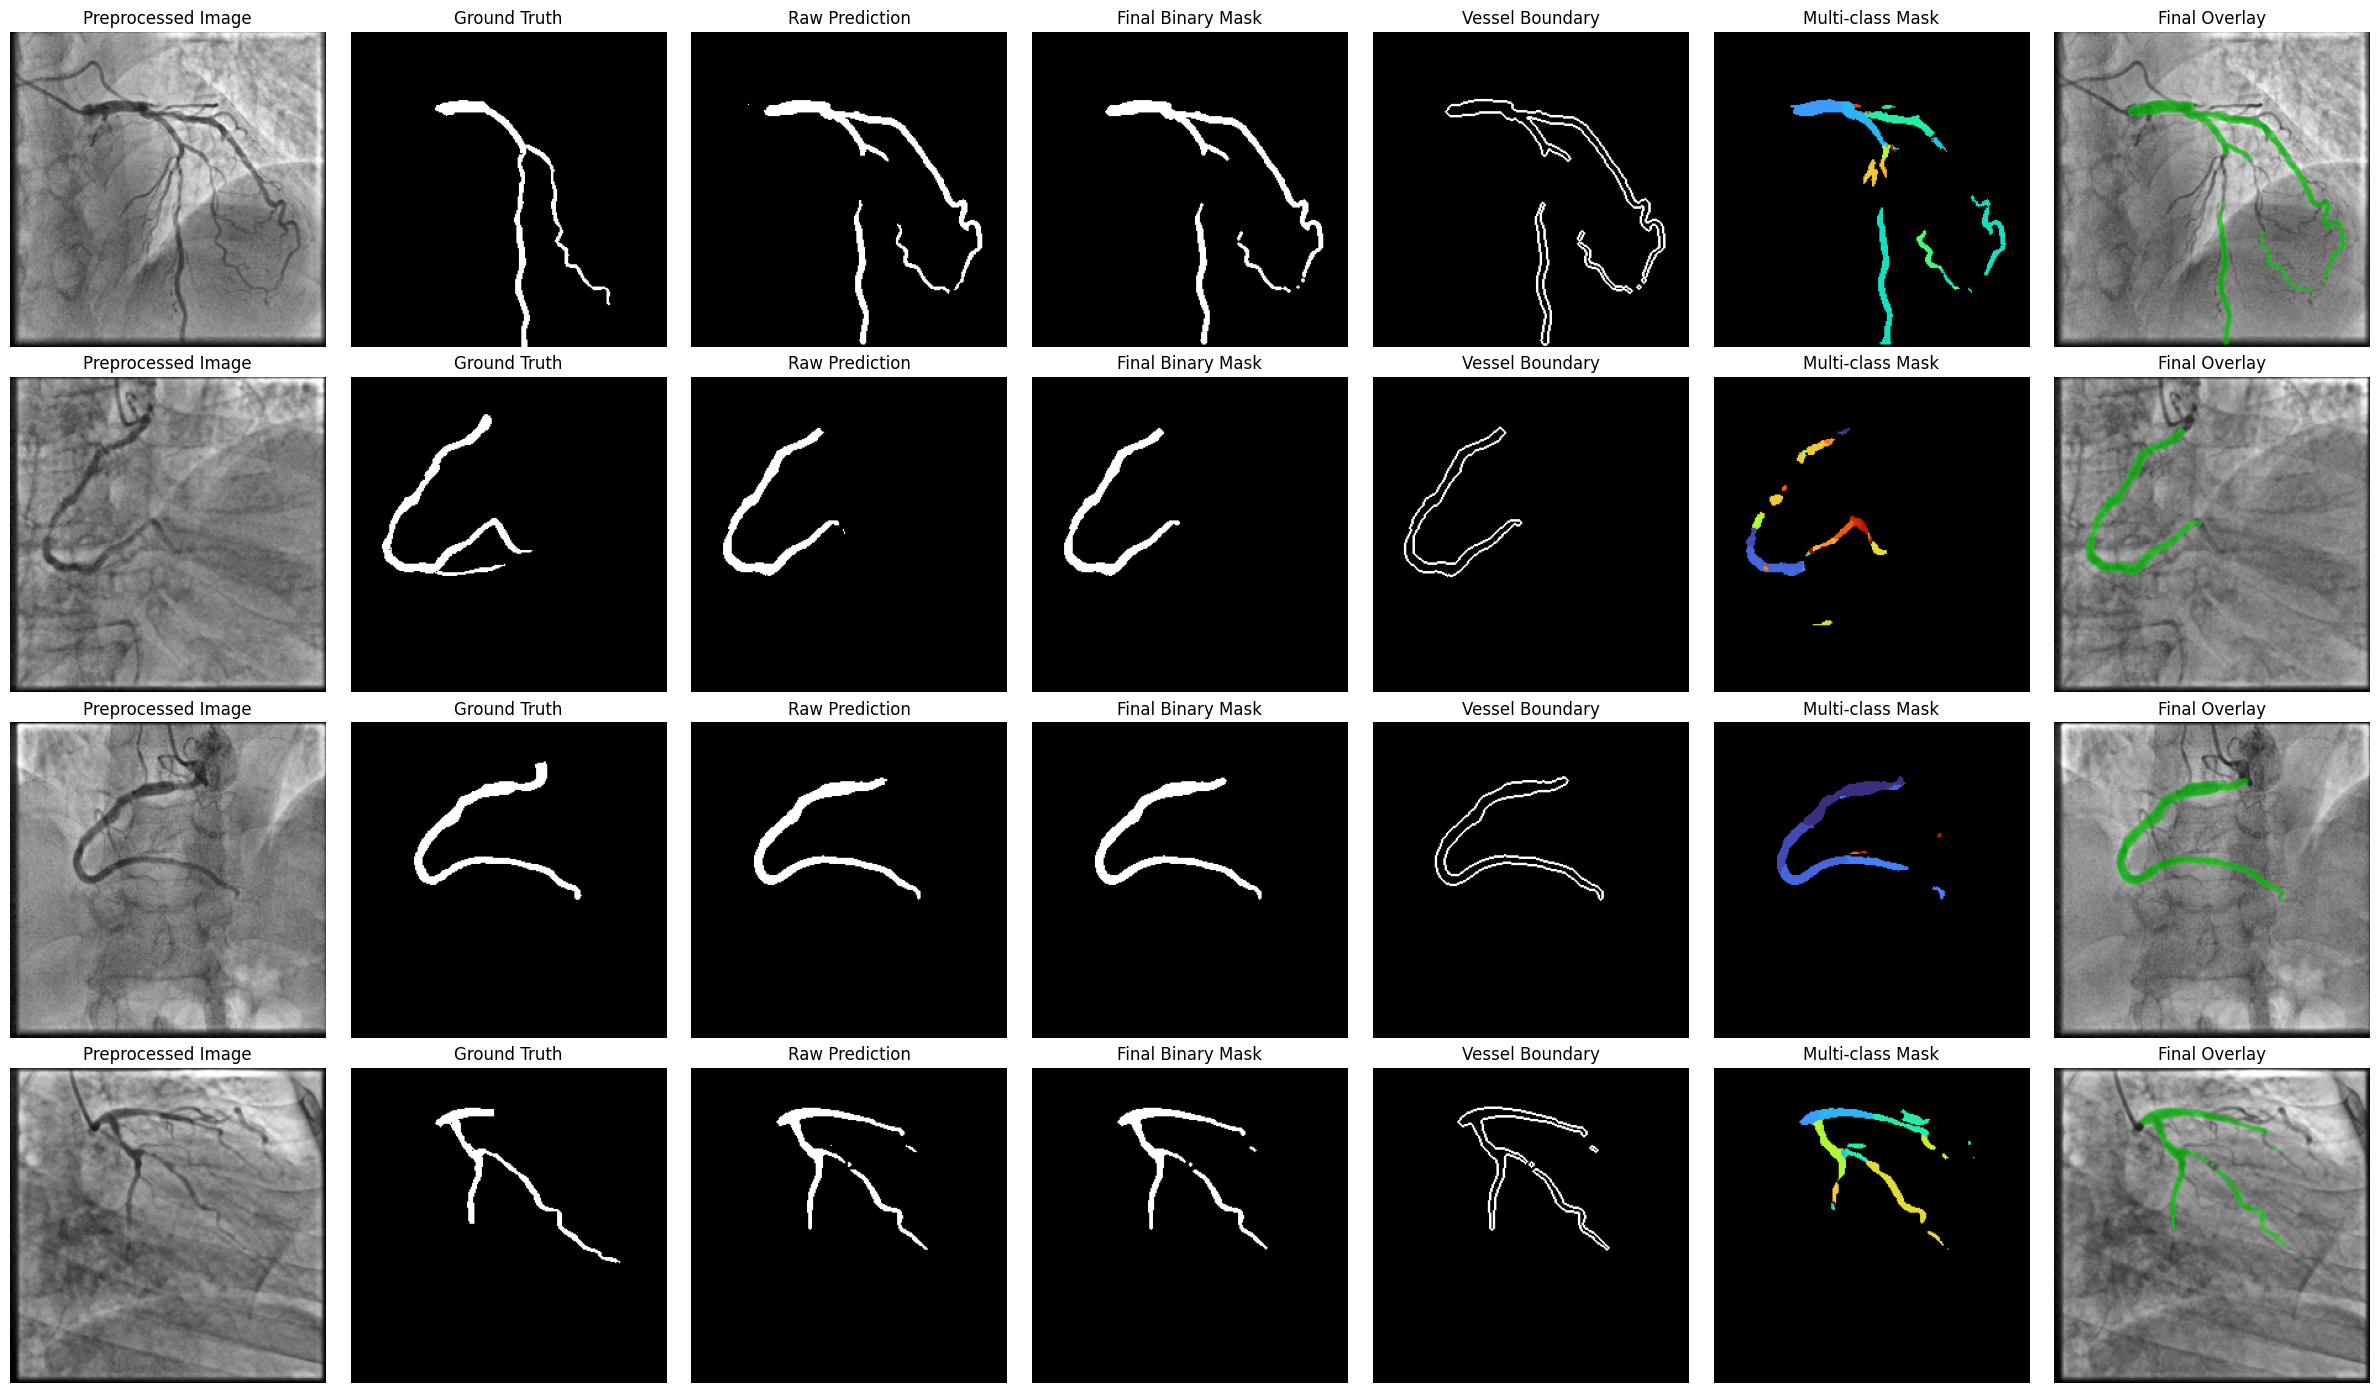

In [37]:
from matplotlib.colors import ListedColormap

class_colors = plt.cm.turbo(
    np.linspace(0, 1, NUM_CLASSES)
)

class_colors[0] = [0, 0, 0, 1]

class_cmap = ListedColormap(class_colors)

fig, axes = plt.subplots(
    4, 7,
    figsize=(24, 14)
)

for i in range(4):

    image, target = test_data[i]

    image_id = test_data.ids[i]

    raw = cv2.imread(
        str(
            OUT / "masks" /
            f"{image_id}_raw.png"
        ),
        0
    )

    mask = cv2.imread(
        str(
            OUT / "masks" /
            f"{image_id}_mask.png"
        ),
        0
    )

    boundary = cv2.imread(
        str(
            OUT / "boundaries" /
            f"{image_id}.png"
        ),
        0
    )

    multi = np.load(
        OUT / "masks" /
        f"{image_id}_multiclass.npy"
    )

    overlay = cv2.imread(
        str(
            OUT / "overlays" /
            f"{image_id}.png"
        )
    )

    overlay = cv2.cvtColor(
        overlay,
        cv2.COLOR_BGR2RGB
    )

    panels = [
        (image[0].numpy(), "Preprocessed Image", "gray"),
        (target[0].numpy(), "Ground Truth", "gray"),
        (raw, "Raw Prediction", "gray"),
        (mask, "Final Binary Mask", "gray"),
        (boundary, "Vessel Boundary", "gray"),
        (multi, "Multi-class Mask", class_cmap),
        (overlay, "Final Overlay", None)
    ]

    for j, (img, title, cmap) in enumerate(panels):

        if j == 5:
            axes[i, j].imshow(
                img,
                cmap=cmap,
                vmin=0,
                vmax=NUM_CLASSES - 1
            )
        else:
            axes[i, j].imshow(img, cmap=cmap)

        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.tight_layout()

plt.savefig(
    OUT / "final_segmentation_visualization.png",
    dpi=200
)

plt.show()